<a href="https://colab.research.google.com/github/Bhokwe/WTM_DataScience_Mentorship/blob/main/ASSIGNMENT_%7C_WEEK_1%7C_WEEK_2%7C_WEEK_3%7C_WEEK_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plot

dataset_path = '/content/drive/MyDrive/Mentorship Datasets/archive/olist_orders_dataset.csv'
dataset_path_1 = '/content/drive/MyDrive/Mentorship Datasets/archive/olist_order_items_dataset.csv'
dataset_path_2 = '/content/drive/MyDrive/Mentorship Datasets/archive/olist_order_reviews_dataset.csv'
dataset_path_3 = '/content/drive/MyDrive/Mentorship Datasets/archive/olist_products_dataset.csv'

In [2]:
df = pd.read_csv(dataset_path)
df2_rev = pd.read_csv(dataset_path_2)
df3_prod = pd.read_csv(dataset_path_3)


In [3]:
# Question 1: How many orders are in the dataset?

df.info()

#there are 99441 rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [4]:
# Question 2: What are the available order statuses?
diff_order_statuses = df['order_status'].unique()
print(diff_order_statuses)
#there are 8 different order statuses

['delivered' 'invoiced' 'shipped' 'processing' 'unavailable' 'canceled'
 'created' 'approved']


In [5]:
# Question 3: How many orders exist for each status?
print(df['order_status'].value_counts())


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [6]:
# Question 4: Which status has the most orders?
print(df['order_status'].value_counts().idxmax())

delivered


In [7]:
# Create a DataFrame containing only delivered orders
delivered_orders = df[df["order_status"] == "delivered"].copy()
print(delivered_orders)

                               order_id                       customer_id  \
0      e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1      53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2      47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3      949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4      ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   
...                                 ...                               ...   
99436  9c5dedf39a927c1b2549525ed64a053c  39bd1228ee8140590ac3aca26f2dfe00   
99437  63943bddc261676b46f01ca7ac2f7bd8  1fca14ff2861355f6e5f14306ff977a7   
99438  83c1379a015df1e13d02aae0204711ab  1aa71eb042121263aafbe80c1b562c9c   
99439  11c177c8e97725db2631073c19f07b62  b331b74b18dc79bcdf6532d51e1637c1   
99440  66dea50a8b16d9b4dee7af250b4be1a5  edb027a75a1449115f6b43211ae02a24   

      order_status order_purchase_timestamp    order_approved_at  \
0      

In [8]:
# Count the delivered orders
#delivered_orders = df[(df["order_status"] == "delivered")]
#len(delivered_orders)
print(delivered_orders.shape[0])

96478


# SELLER ANALYSIS

In [9]:
dataset_path_1 = '/content/drive/MyDrive/Mentorship Datasets/archive/olist_order_items_dataset.csv'
df1 = pd.read_csv(dataset_path_1)

In [10]:
df1.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [11]:
# Calculate total sales per seller.
total_sales = (
     df1.groupby('seller_id')['price'].sum().sort_values(ascending=False)
 )
#print(total_sales.count)
total_sales.head(20)



,price
seller_id,
4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
53243585a1d6dc2643021fd1853d8905,222776.05
4a3ca9315b744ce9f8e9374361493884,200472.92
fa1c13f2614d7b5c4749cbc52fecda94,194042.03
7c67e1448b00f6e969d365cea6b010ab,187923.89
7e93a43ef30c4f03f38b393420bc753a,176431.87
da8622b14eb17ae2831f4ac5b9dab84a,160236.57
7a67c85e85bb2ce8582c35f2203ad736,141745.53
1025f0e2d44d7041d6cf58b6550e0bfa,138968.55


In [12]:
# Calculate average item price per seller.
avg_sales = (
     df1.groupby('seller_id')['price'].mean().sort_values(ascending=False)
 )
avg_sales.head(10)

,price
seller_id,
80ceebb4ee9b31afb6c6a916a574a1e2,6729.000000
ee27a8f15b1dded4d213a468ba4eb391,6499.000000
585175ec331ea177fa47199e39a6170a,3549.000000
abe021b01ba992245271b9aa422032df,3360.000000
a00824eb9093d40e589b940ec45c4eb0,3133.323333
e2a1ac9bf33e5549a2a4f834e70df2f8,2999.890000
e908c0f3646e8b60375734a350d95d71,2951.000000
d63c73efd41eb002280e7ec831424edb,2799.000000
1444c08e64d55fb3c25f0f09c07ffcf2,2749.000000


In [13]:
# Count the number of items per seller.
items_sold = (
     df1.groupby('seller_id')['order_item_id'].count().sort_values(ascending=False)
 )
items_sold.head(10)

,order_item_id
seller_id,
6560211a19b47992c3666cc44a7e94c0,2033
4a3ca9315b744ce9f8e9374361493884,1987
1f50f920176fa81dab994f9023523100,1931
cc419e0650a3c5ba77189a1882b7556a,1775
da8622b14eb17ae2831f4ac5b9dab84a,1551
955fee9216a65b617aa5c0531780ce60,1499
1025f0e2d44d7041d6cf58b6550e0bfa,1428
7c67e1448b00f6e969d365cea6b010ab,1364
ea8482cd71df3c1969d7b9473ff13abc,1203


In [14]:
# Sort sellers by total sales.
total_sales = (
     df1.groupby('seller_id')['price'].sum().sort_values(ascending=False)
 )
#print(total_sales.count())
total_sales.head(20)

,price
seller_id,
4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
53243585a1d6dc2643021fd1853d8905,222776.05
4a3ca9315b744ce9f8e9374361493884,200472.92
fa1c13f2614d7b5c4749cbc52fecda94,194042.03
7c67e1448b00f6e969d365cea6b010ab,187923.89
7e93a43ef30c4f03f38b393420bc753a,176431.87
da8622b14eb17ae2831f4ac5b9dab84a,160236.57
7a67c85e85bb2ce8582c35f2203ad736,141745.53
1025f0e2d44d7041d6cf58b6550e0bfa,138968.55


In [15]:
# Display the top 10 sellers.
total_sales = (
     df1.groupby('seller_id')['price'].sum().sort_values(ascending=False)
 )
#print(total_sales.count())
total_sales.head(10)

,price
seller_id,
4869f7a5dfa277a7dca6462dcf3b52b2,229472.63
53243585a1d6dc2643021fd1853d8905,222776.05
4a3ca9315b744ce9f8e9374361493884,200472.92
fa1c13f2614d7b5c4749cbc52fecda94,194042.03
7c67e1448b00f6e969d365cea6b010ab,187923.89
7e93a43ef30c4f03f38b393420bc753a,176431.87
da8622b14eb17ae2831f4ac5b9dab84a,160236.57
7a67c85e85bb2ce8582c35f2203ad736,141745.53
1025f0e2d44d7041d6cf58b6550e0bfa,138968.55


INDIVIDUAL PRACTICAL ASSESSMENT

In [16]:
# 1. Inspect your selected table
print("--- DATASET SHAPE & TYPES ---")
print(df1.info())
print("\n--- MISSING VALUES ---")
print(df1.isnull().sum())
print("\n--- SUMMARY STATISTICS ---")
print(df1[['price', 'freight_value']].describe())

--- DATASET SHAPE & TYPES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB
None

--- MISSING VALUES ---
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

--- SUMMARY STATISTICS ---
               price  freight_value
count  112650.000000  112650.000000
mean      120.653739  

In [17]:
# 2. Select useful columns
items_subset = df1[['order_id', 'product_id', 'seller_id', 'price', 'freight_value']]
print("\n--- SUBSET HEAD ---")
print(items_subset.head())


--- SUBSET HEAD ---
                           order_id                        product_id  \
0  00010242fe8c5a6d1ba2dd792cb16214  4244733e06e7ecb4970a6e2683c13e61   
1  00018f77f2f0320c557190d7a144bdd3  e5f2d52b802189ee658865ca93d83a8f   
2  000229ec398224ef6ca0657da4fc703e  c777355d18b72b67abbeef9df44fd0fd   
3  00024acbcdf0a6daa1e931b038114c75  7634da152a4610f1595efa32f14722fc   
4  00042b26cf59d7ce69dfabb4e55b4fd9  ac6c3623068f30de03045865e4e10089   

                          seller_id   price  freight_value  
0  48436dade18ac8b2bce089ec2a041202   58.90          13.29  
1  dd7ddc04e1b6c2c614352b383efe2d36  239.90          19.93  
2  5b51032eddd242adc84c38acab88f23d  199.00          17.87  
3  9d7a1d34a5052409006425275ba1c2b4   12.99          12.79  
4  df560393f3a51e74553ab94004ba5c87  199.90          18.14  


In [18]:
# 3. Filter records (Products with price > 1000)
high_value_items = items_subset[items_subset['price'] > 1000]
print(f"\nTotal high-value items (> $1,000): {len(high_value_items)}")


Total high-value items (> $1,000): 844


In [19]:
# 4. Sort records (Top 5 most expensive single items)
top_expensive = items_subset.sort_values(by='price', ascending=False).head(5)
print("\n--- TOP 5 EXPENSIVE ITEMS ---")
print(top_expensive[['product_id', 'price', 'freight_value']])


--- TOP 5 EXPENSIVE ITEMS ---
                              product_id   price  freight_value
3556    489ae2aa008f021502940f251d4cce7f  6735.0         194.31
112233  69c590f7ffc7bf8db97190b6cb6ed62e  6729.0         193.21
107841  1bdf5e6731585cf01aa8169c7028d6ad  6499.0         227.66
74336   a6492cc69376c469ab6f61d8f44de961  4799.0         151.34
11249   c3ed642d592594bb648ff4a04cee2747  4690.0          74.34


In [20]:
# 5. Group and aggregate (Seller performance metrics)
seller_summary = items_subset.groupby('seller_id').agg(
    total_revenue=('price', 'sum'),
    avg_price=('price', 'mean'),
    items_sold=('product_id', 'count'),
    avg_freight=('freight_value', 'mean')
).reset_index()
print(seller_summary)

                             seller_id  total_revenue   avg_price  items_sold  \
0     0015a82c2db000af6aaaf3ae2ecb0532        2685.00  895.000000           3   
1     001cca7ae9ae17fb1caed9dfb1094831       25080.03  104.937364         239   
2     001e6ad469a905060d959994f1b41e4f         250.00  250.000000           1   
3     002100f778ceb8431b7a1020ff7ab48f        1234.50   22.445455          55   
4     003554e2dce176b5555353e4f3555ac8         120.00  120.000000           1   
...                                ...            ...         ...         ...   
3090  ffcfefa19b08742c5d315f2791395ee5          69.90   69.900000           1   
3091  ffdd9f82b9a447f6f8d4b91554cc7dd3        2101.20  105.060000          20   
3092  ffeee66ac5d5a62fe688b9d26f83f534        1839.86  131.418571          14   
3093  fffd5413c0700ac820c7069d66d98c89        9062.30  148.562295          61   
3094  ffff564a4f9085cd26170f4732393726        1426.30   71.315000          20   

      avg_freight  
0      

In [21]:
# Sort top sellers by total revenue
top_sellers = seller_summary.sort_values(by='total_revenue', ascending=False).head(10)
print("\n--- TOP 10 SELLERS BY REVENUE ---")
print(top_sellers)


--- TOP 10 SELLERS BY REVENUE ---
                             seller_id  total_revenue   avg_price  items_sold  \
857   4869f7a5dfa277a7dca6462dcf3b52b2      229472.63  198.505735        1156   
1013  53243585a1d6dc2643021fd1853d8905      222776.05  543.356220         410   
881   4a3ca9315b744ce9f8e9374361493884      200472.92  100.892260        1987   
3024  fa1c13f2614d7b5c4749cbc52fecda94      194042.03  331.129744         586   
1535  7c67e1448b00f6e969d365cea6b010ab      187923.89  137.774113        1364   
1560  7e93a43ef30c4f03f38b393420bc753a      176431.87  518.917265         340   
2643  da8622b14eb17ae2831f4ac5b9dab84a      160236.57  103.311779        1551   
1505  7a67c85e85bb2ce8582c35f2203ad736      141745.53  121.046567        1171   
192   1025f0e2d44d7041d6cf58b6550e0bfa      138968.55   97.316912        1428   
1824  955fee9216a65b617aa5c0531780ce60      135171.70   90.174583        1499   

      avg_freight  
857     17.446427  
1013    31.903976  
881     17.64

Finding 1
The distribution of product prices is heavily right-skewed. While the average item price sits around 120 Brazilian Real, the median is substantially lower at roughly 75 Real. This shows that the vast majority of catalog purchases are low-to-mid value items, with the average being pulled upward by a few rare luxury items exceeding 1,000 Real.


Finding 2
Total sales volume is driven by a small concentration of top merchants. The top 10 sellers generate a disproportionate amount of total revenue. This is driven primarily by sheer sales volume, selling thousands of units, rather than charging exceptionally high individual prices.


Finding 3
Freight charges vary widely and do not scale proportionally with item prices. Lower-priced items frequently carry shipping costs that make up 25 to 50 percent or more of the item price. This creates a major friction point for cart abandonment, unlike high-ticket items where shipping is only a tiny fraction of the total cost.

The analysis of the order_items dataset indicates that Olist operates primarily as a high-volume marketplace for everyday, accessible goods rather than a luxury storefront.   

Key Discovery: Revenue generation is dominated by high-turnover sellers moving moderately priced goods, with a heavy long-tail of low-volume vendors.

Most Interesting Result: The ratio of freight cost to product price on everyday goods is disproportionately high, often making shipping a significant fraction of the subtotal.

Business Decision: Marketplace management should focus partner acquisition and account management resources on retaining the top 5% revenue-generating merchants. Concurrently, launching subsidized flat-rate shipping or bundled fulfillment thresholds for lower-priced items would reduce shipping friction and improve basket conversion rates.

# *ASSIGNMENT 2*

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


# Research Question
Do customers typically receive their orders earlier than the estimated delivery date provided at checkout, and is this difference statistically significant?

In [23]:
df.head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


# Variables
Actual Delivery Time (Days): The difference between order_delivered_customer_date and order_purchase_timestamp. This represents the reality of the shipping timeframe.

Estimated Delivery Time (Days): The difference between order_estimated_delivery_date and order_purchase_timestamp. This represents the expectation set with the customer.

Delivery Error (Days): The difference between the Estimated Delivery Time and the Actual Delivery Time. A positive number means the order arrived early; a negative number means it was late.

In [24]:
df.describe()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [26]:
#converting the string dates to datetime objects
date_columns = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_columns:
    df[col] = pd.to_datetime(df[col])

In [27]:
#calculating variables in days
df['actual_delivery_time'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400
df['estimated_delivery_time'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400
df['delivery_error'] = df['estimated_delivery_time'] - df['actual_delivery_time']

In [28]:
#remove orders that were never delivered (missing values)
df_clean = df.dropna(subset=['actual_delivery_time', 'estimated_delivery_time']).copy()
df_clean.describe()

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_time,estimated_delivery_time,delivery_error
count,96476,96462,96475,96476,96476,96476.000000,96476.000000,96476.000000
mean,2018-01-01 22:44:47.156474368,2018-01-02 10:08:41.350552576,2018-01-05 04:14:08.754413056,2018-01-14 12:09:19.035542784,2018-01-25 16:27:14.993158656,12.558702,23.737822,11.179120
min,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-10-04 00:00:00,0.533414,2.008009,-188.975081
25%,2017-09-14 08:10:58,2017-09-14 14:30:16,2017-09-18 16:21:06,2017-09-25 22:07:22.249999872,2017-10-05 00:00:00,6.766403,18.330014,6.390000
50%,2018-01-20 19:21:46,2018-01-22 13:48:57,2018-01-24 15:55:11,2018-02-02 19:28:10.500000,2018-02-16 00:00:00,10.217755,23.231343,11.948941
75%,2018-05-05 18:28:21.750000128,2018-05-06 10:30:44.750000128,2018-05-08 14:32:00,2018-05-15 22:48:52.249999872,2018-05-28 00:00:00,15.720327,28.408371,16.244384
max,2018-08-29 15:00:37,2018-08-29 15:10:26,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-10-25 00:00:00,209.628611,155.135463,146.016123
std,NaN,NaN,NaN,NaN,NaN,9.546530,8.763466,10.186113


In [29]:
#view the stats for the variables I chose
print(df_clean[['actual_delivery_time', 'estimated_delivery_time', 'delivery_error']].describe())

# printing the medians for a quick comparison
print("\nMedians:")
print(df_clean[['actual_delivery_time', 'estimated_delivery_time', 'delivery_error']].median())

       actual_delivery_time  estimated_delivery_time  delivery_error
count          96476.000000             96476.000000    96476.000000
mean              12.558702                23.737822       11.179120
std                9.546530                 8.763466       10.186113
min                0.533414                 2.008009     -188.975081
25%                6.766403                18.330014        6.390000
50%               10.217755                23.231343       11.948941
75%               15.720327                28.408371       16.244384
max              209.628611               155.135463      146.016123

Medians:
actual_delivery_time       10.217755
estimated_delivery_time    23.231343
delivery_error             11.948941
dtype: float64


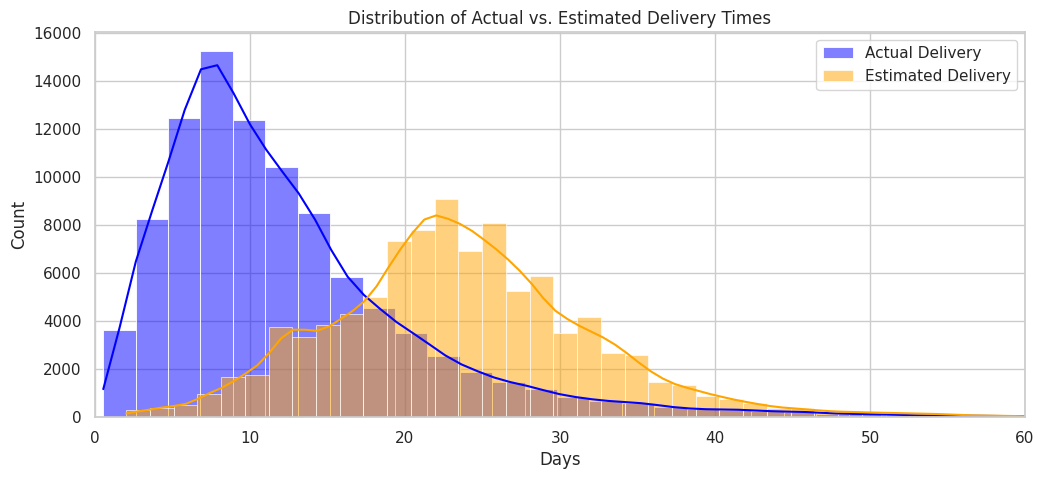

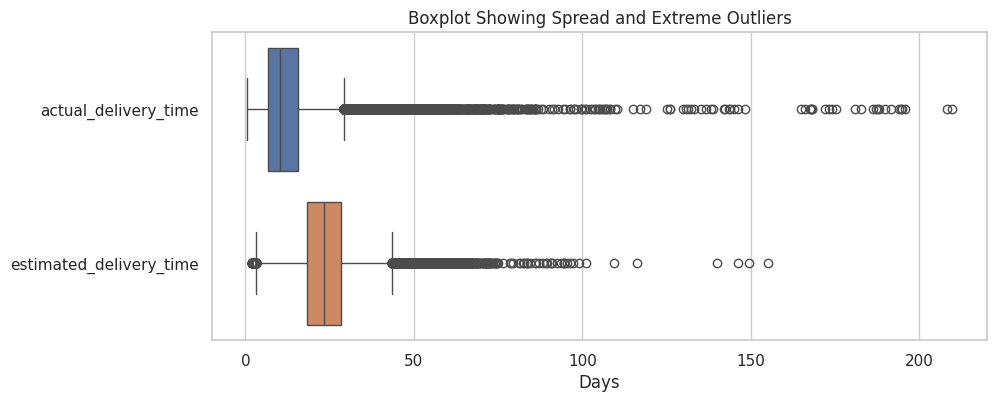

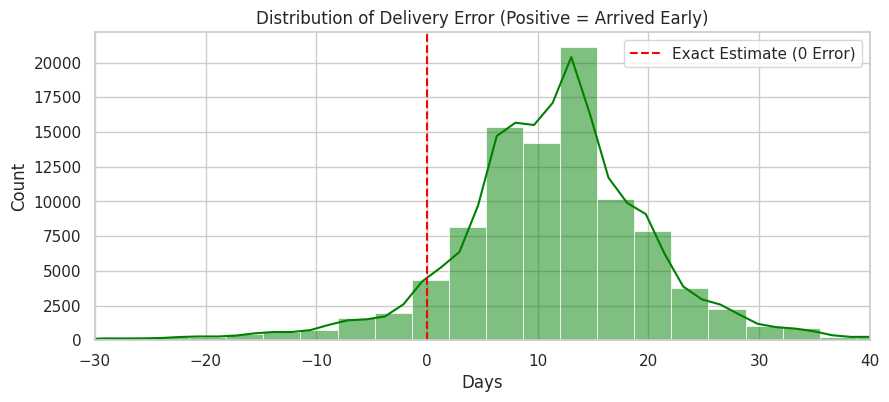

In [30]:
sns.set_theme(style="whitegrid")

# 1. Distribution: Histograms
plt.figure(figsize=(12, 5))
sns.histplot(df_clean['actual_delivery_time'], bins=100, color='blue', alpha=0.5, label='Actual Delivery', kde=True)
sns.histplot(df_clean['estimated_delivery_time'], bins=100, color='orange', alpha=0.5, label='Estimated Delivery', kde=True)

# Limiting the x-axis to 60 days removes extreme outliers from the plot so you can see the main shape
plt.xlim(0, 60)
plt.title('Distribution of Actual vs. Estimated Delivery Times')
plt.xlabel('Days')
plt.legend()
plt.show()

# 2. Outliers and Spread: Boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean[['actual_delivery_time', 'estimated_delivery_time']], orient='h')
plt.title('Boxplot Showing Spread and Extreme Outliers')
plt.xlabel('Days')
plt.show()

# 3. Delivery Error Distribution
plt.figure(figsize=(10, 4))
sns.histplot(df_clean['delivery_error'], bins=100, color='green', kde=True)
plt.axvline(0, color='red', linestyle='--', label='Exact Estimate (0 Error)')
plt.xlim(-30, 40)
plt.title('Distribution of Delivery Error (Positive = Arrived Early)')
plt.xlabel('Days')
plt.legend()
plt.show()

In [31]:
# 1. Wilcoxon Signed-Rank Test (Recommended)
# We use this because the boxplots showed heavy extreme outliers.
stats_w, p_val_w = stats.wilcoxon(df_clean['estimated_delivery_time'], df_clean['actual_delivery_time'])

print("--- Wilcoxon Signed-Rank Test ---")
print(f"Test Statistic: {stats_w}")
print(f"P-value: {p_val_w}\n")

# 2. Paired T-Test (Alternative)
stat_t, p_val_t = stats.ttest_rel(df_clean['estimated_delivery_time'], df_clean['actual_delivery_time'])

print("--- Paired T-Test ---")
print(f"Test Statistic: {stat_t:.2f}")
print(f"P-value: {p_val_t}")

--- Wilcoxon Signed-Rank Test ---
Test Statistic: 233109658.0
P-value: 0.0

--- Paired T-Test ---
Test Statistic: 340.89
P-value: 0.0


# Statistical Test
A Wilcoxon Signed-Rank Test was performed to compare the actual delivery times against the estimated delivery times for each paired order. The test resulted in a test statistic of 233109658.0 and a p-value of 0.0. The alternative Paired T-Test confirmed this result with a test statistic of 340.89 and a p-value of 0.0.   In plain language, a p-value of 0.0 means the probability of observing this large of a difference purely by random chance is effectively zero. This confirms that the gap between when Olist estimates a package will arrive and when it actually arrives is highly statistically significant.

# Interpretation
The p-value of 0.0 tells us that the consistent gap between estimated and actual delivery times is not a random anomaly. In the context of this dataset, Olist systematically overestimates how long shipping will take. Because the delivery error distribution sits heavily in the positive range, we know that the vast majority of customers are receiving their items days (and sometimes weeks) before the promised date. This indicates that Olist or its sellers likely bake a substantial "buffer" into their delivery estimates to manage customer expectations and absorb potential logistical delays.

# Limitations
Omitted Variables: This analysis treats all orders equally, but delivery times in Brazil are highly dependent on geography. We did not control for the distance between the seller and the customer (e.g., shipping within São Paulo versus shipping to Amazonas), product size, or the specific carrier used, all of which likely impact the delivery error.

Time Period: The Olist dataset covers 2016 to 2018. Brazil's e-commerce logistics and infrastructure have evolved significantly since then, meaning these findings do not necessarily represent current delivery performance.

Correlation vs. Causation: While we established a significant gap, this test cannot prove why the gap exists (e.g., whether it is a deliberate algorithm choice by Olist or a result of sellers padding their handling times).

# Conclusion
Returning to the original research question: We can reasonably conclude that during the 2016–2018 period, Olist customers systematically received their orders earlier than the estimated delivery date provided at checkout, and this difference is highly statistically significant.

However, we cannot conclude whether this strategy of under-promising and over-delivering actually resulted in higher customer satisfaction, as we did not analyze the relationship between delivery error and customer review scores. We also cannot conclude the specific causes behind the extreme delivery delays seen in the outliers.

# ASSIGNMENT 5

# Issue 1

In [32]:
# Evidence & Summary Metrics
missing_delivery = df['order_delivered_customer_date'].isnull().sum()
total_orders = len(df)
print(f"Missing delivery dates: {missing_delivery} out of {total_orders} ({(missing_delivery/total_orders)*100:.2f}%)")

# Defensible Cleaning Plan Code
df['is_delivered'] = (df['order_status'] == 'delivered') & (df['order_delivered_customer_date'].notnull())

Missing delivery dates: 2965 out of 99441 (2.98%)


# Issue 2

In [33]:
# Evidence & Summary Metrics
print(f"Max price: ${df1['price'].max():.2f}")
print(f"Median price: ${df1['price'].median():.2f}")
print(f"Skewness: {df1['price'].skew():.2f}")


df1['price_log'] = np.log1p(df1['price'])

Max price: $6735.00
Median price: $74.99
Skewness: 7.92


# Issue 3

In [34]:
# Evidence & Summary Metrics
missing_categories = df3_prod['product_category_name'].isnull().sum()
print(f"Products missing a category name: {missing_categories}")

df3_prod['product_category_name'] = df3_prod['product_category_name'].fillna('unclassified')

Products missing a category name: 610


# Issue 4

In [35]:
# Evidence & Summary Metrics
duplicate_reviews = df2_rev.duplicated(subset=['review_id']).sum()
print(f"Duplicate review IDs found: {duplicate_reviews}")

reviews = df2_rev.sort_values('review_creation_date').drop_duplicates(subset=['review_id'], keep='last')

Duplicate review IDs found: 814


# Issue 5

In [36]:
# Evidence & Summary Metrics
zero_weight_count = (df3_prod['product_weight_g'] == 0).sum()
print(f"Products listed with 0g weight: {zero_weight_count}")

median_weight = df3_prod.loc[df3_prod['product_weight_g'] > 0, 'product_weight_g'].median()
df3_prod.loc[df3_prod['product_weight_g'] == 0, 'product_weight_g'] = median_weight

Products listed with 0g weight: 4


# DATA VISUALIZATION

# Task 1: Price Distribution & Outliers

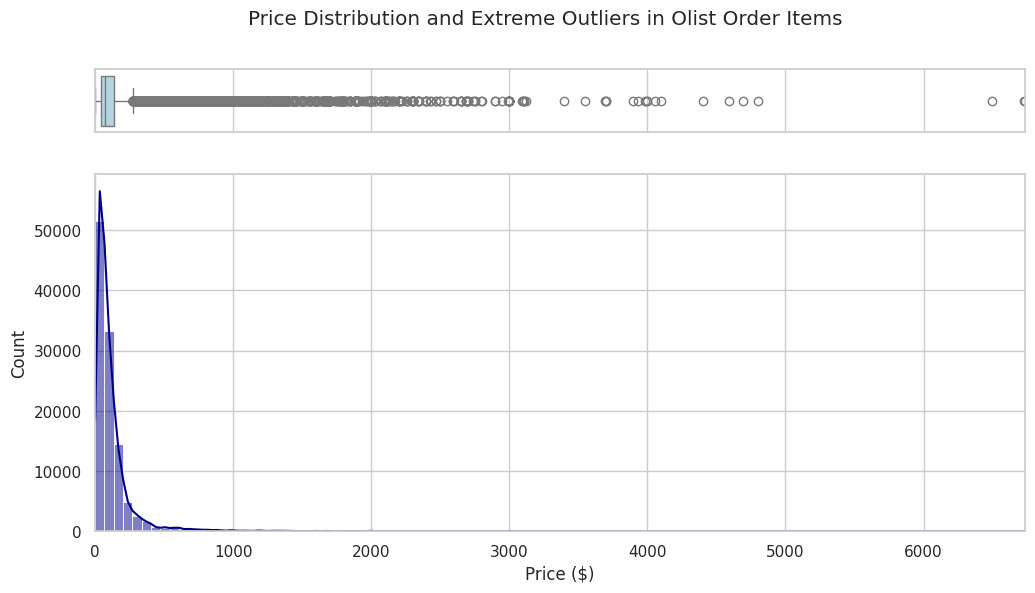

In [37]:
# Set up a composite figure with a boxplot on top and a histogram/KDE below
fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, figsize=(12, 6), gridspec_kw={"height_ratios": (.15, .85)})

# Top plot: Boxplot highlighting the extreme right skew
sns.boxplot(x=df1['price'], ax=ax_box, color='lightblue')
ax_box.set(xlabel='')

# Bottom plot: Histogram with KDE
sns.histplot(x=df1['price'], ax=ax_hist, bins=100, kde=True, color='darkblue')

plt.suptitle('Price Distribution and Extreme Outliers in Olist Order Items')
plt.xlabel('Price ($)')
plt.xlim(0, df1['price'].max())
plt.show()

# Task 2: Order Status Breakdown

/tmp/ipykernel_6298/3358919098.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='order_status', order=df['order_status'].value_counts().index, palette='viridis')


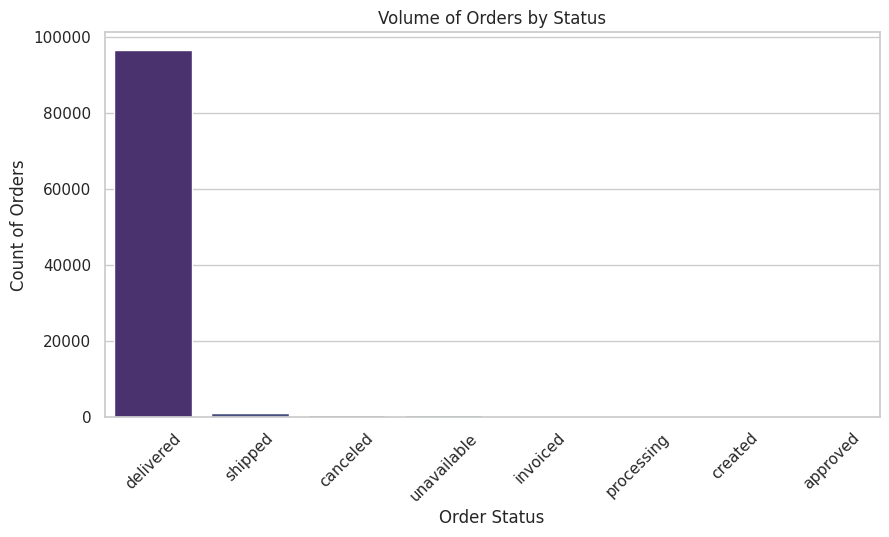

In [38]:
plt.figure(figsize=(10, 5))
# A bar plot ordered by the most frequent statuses
sns.countplot(data=df, x='order_status', order=df['order_status'].value_counts().index, palette='viridis')

plt.title('Volume of Orders by Status')
plt.xlabel('Order Status')
plt.ylabel('Count of Orders')
plt.xticks(rotation=45)
plt.show()

# Relection

While summary statistics like .isnull().sum() or .describe() offer immediate, quantifiable baseline checks, they often mask the true behavioral shape of the data. As observed in earlier Olist dataset analyses where actual delivery times showed extreme anomalies extending past 200 days, a simple median or mean fails to convey the severity of a long-tail distribution. The composite visualizations in Part B immediately reveal not just the existence of outliers, but exactly how densely clustered the normal transaction volumes are compared to the sparse, extreme anomalies stretching far along the x-axis.

Blindly applying df.dropna() or blanket-dropping statistical outliers is highly destructive in an e-commerce context because it frequently deletes legitimate, high-value business data. Using Issue 2 (Extreme Outliers in Product Prices) as an example, an item priced at $6,735.00 is a severe statistical anomaly compared to the $74.90 median, but it represents an authentic, completed transaction. Dropping these rows would permanently erase revenue from financial reports, resulting in inaccurate sales totals. Instead, isolating these records or applying mathematical transformations (like log scaling) preserves the integrity of the transactional database for business intelligence while preventing the extreme values from distorting predictive machine learning algorithms.

# SESSION 6 ASSIGNMENT

# Question 1

In [39]:
import sqlite3


conn = sqlite3.connect(':memory:')


df.to_sql('orders', conn, index=False, if_exists='replace')
df1.to_sql('order_items', conn, index=False, if_exists='replace')
df2_rev.to_sql('reviews', conn, index=False, if_exists='replace')
df3_prod.to_sql('products', conn, index=False, if_exists='replace')

# Question 1
query = """
SELECT *
FROM orders
LIMIT 10;
"""


result_df = pd.read_sql(query, conn)
display(result_df)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_time,estimated_delivery_time,delivery_error,is_delivered
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,8.436574,15.544063,7.107488,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,13.782037,19.137766,5.355729,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,9.394213,26.639711,17.245498,1
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,13.208750,26.188819,12.980069,1
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2.873877,12.112049,9.238171,1
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00,16.542245,22.085359,5.543113,1
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,None,None,2017-05-09 00:00:00,NaN,27.484630,NaN,0
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00,9.989826,21.451042,11.461215,1
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00,9.818762,41.229757,31.410995,1
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00,18.221852,24.503449,6.281597,1


# Explanation

Running this query returns the first 10 rows of the orders table. This provides a quick preview of the dataset's structure, confirming the available columns (like order IDs and timestamps) and the data types stored within them.

# Question 2

In [40]:
query = """
SELECT *
FROM orders
WHERE order_status = 'delivered';
"""

result_df = pd.read_sql(query, conn)
display(result_df)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,actual_delivery_time,estimated_delivery_time,delivery_error,is_delivered
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,8.436574,15.544063,7.107488,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,13.782037,19.137766,5.355729,1
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,9.394213,26.639711,17.245498,1
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,13.208750,26.188819,12.980069,1
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2.873877,12.112049,9.238171,1
...,...,...,...,...,...,...,...,...,...,...,...,...
96473,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,8.218009,18.587442,10.369433,1
96474,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,22.193727,23.459051,1.265324,1
96475,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,24.859421,30.384225,5.524803,1
96476,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,17.086424,37.105243,20.018819,1


### Explanation

This query filters the dataset to output only the records where the delivery successfully reached the customer. It isolates completed transactions, which is essential for analyzing finalized sales or calculating actual delivery times without interference from canceled or in-transit orders.

# Question 3

In [41]:
query = """
SELECT COUNT(*) AS total_orders
FROM orders;
"""

result_df = pd.read_sql(query, conn)
display(result_df)

,total_orders
0,99441


### Explanation

Executing this query yields a single numeric value representing the total number of rows in the table. This tells you the absolute historical volume of orders processed by the platform, serving as a baseline figure for overall business scale.

# Question 4

In [42]:
query = """
SELECT order_status, COUNT(*) AS status_count
FROM orders
GROUP BY order_status;
"""

result_df = pd.read_sql(query, conn)
display(result_df)

,order_status,status_count
0,approved,2
1,canceled,625
2,created,5
3,delivered,96478
4,invoiced,314
5,processing,301
6,shipped,1107
7,unavailable,609


### Explanation

This result aggregates the data to show exactly how many orders fall into each specific category (e.g., delivered, shipped, canceled, invoiced). It provides a clear snapshot of the operational health and pipeline distribution of all tracked purchases.

Question 5

In [43]:
query = """
SELECT order_status, COUNT(*) AS status_count
FROM orders
GROUP BY order_status
ORDER BY status_count DESC;
"""

result_df = pd.read_sql(query, conn)
display(result_df)

,order_status,status_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


### Explanation

By sorting the grouped counts from highest to lowest, this output immediately ranks the frequency of each order state. It demonstrates that successfully delivered orders make up the overwhelming majority of the business volume, while pushing rare occurrences (like unavailable or canceled orders) to the bottom of the list.

# ASSIGNMENT 7

In [54]:
# Distinct Statuses
#dataframes to SQL
df.to_sql('orders', conn, index=False, if_exists='replace')
df1.to_sql('order_items', conn, index=False, if_exists='replace')
df2_rev.to_sql('reviews', conn, index=False, if_exists='replace')
df3_prod.to_sql('products', conn, index=False, if_exists='replace')

query = """SELECT DISTINCT order_status
FROM orders;"""
result_df = pd.read_sql(query, conn)
display(result_df)



,order_status
0,delivered
1,invoiced
2,shipped
3,processing
4,unavailable
5,canceled
6,created
7,approved


In [58]:
# Price Summary
query = """SELECT
    MIN(price) AS min_price,
    AVG(price) AS avg_price,
    MAX(price) AS max_price
FROM order_items;"""
result_df = pd.read_sql(query, conn)
display(result_df)


,min_price,avg_price,max_price
0,0.85,120.653739,6735.0


In [60]:
# Delivered Orders
query = """SELECT COUNT(*) AS delivered_order_count
FROM orders
WHERE order_status = 'delivered';"""
result_df =pd.read_sql(query,conn)
display(result_df)


,delivered_order_count
0,96478


In [61]:
# Low Review Ratings
query = """SELECT
    oi.product_id,
    p.product_category_name,
    r.review_score
FROM reviews r
JOIN order_items oi ON r.order_id = oi.order_id
JOIN products p ON oi.product_id = p.product_id
WHERE r.review_score = 1;"""

result_df = pd.read_sql(query,conn)
display(result_df)

,product_id,product_category_name,review_score
0,4e3550b4ebca5e32ccc3d32b3470e31f,cama_mesa_banho,1
1,c45d02cc82cd779835094de9b29272cb,cama_mesa_banho,1
2,c45d02cc82cd779835094de9b29272cb,cama_mesa_banho,1
3,c45d02cc82cd779835094de9b29272cb,cama_mesa_banho,1
4,55a1e3d39ace9c0b217f6c30b04d43c0,malas_acessorios,1
...,...,...,...
14230,d394d30215872be4cda2c67c1ce5b981,esporte_lazer,1
14231,0a57f7d2c983bcf8188589a5fea4a8da,relogios_presentes,1
14232,3150c2690393e7ea7c2b3acf2479ec8c,bebes,1
14233,d8342ac8b27a03e8d25280c296dfa830,moveis_decoracao,1


In [62]:
# High Value Categories
query = """SELECT
    p.product_category_name,
    AVG(oi.price) AS avg_price
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
WHERE p.product_category_name IS NOT NULL
GROUP BY p.product_category_name
HAVING AVG(oi.price) > 150;"""
result_df = pd.read_sql(query,conn)
display(result_df)

,product_category_name,avg_price
0,agro_industria_e_comercio,342.124858
1,climatizacao,185.269226
2,construcao_ferramentas_construcao,155.734758
3,construcao_ferramentas_ferramentas,154.407282
4,construcao_ferramentas_seguranca,208.992371
5,cool_stuff,167.357969
6,eletrodomesticos_2,476.124958
7,eletroportateis,280.778468
8,instrumentos_musicais,281.616000
9,moveis_cozinha_area_de_servico_jantar_e_jardim,164.869644


In [63]:
# Average Freight
query = """SELECT AVG(freight_value) AS avg_freight_value
FROM order_items;"""

result_df = pd.read_sql(query,conn)
display(result_df)

,avg_freight_value
0,19.99032


In [64]:
# Top 5 prices
query ="""SELECT
    order_id,
    price
FROM order_items
ORDER BY price DESC
LIMIT 5;"""
result_df = pd.read_sql(query,conn)
display(result_df)

,order_id,price
0,0812eb902a67711a1cb742b3cdaa65ae,6735.0
1,fefacc66af859508bf1a7934eab1e97f,6729.0
2,f5136e38d1a14a4dbd87dff67da82701,6499.0
3,a96610ab360d42a2e5335a3998b4718a,4799.0
4,199af31afc78c699f0dbf71fb178d4d4,4690.0


In [65]:
# Specific Category Lookup
query = """SELECT
    oi.order_id,
    p.product_category_name
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
WHERE oi.order_id = '00010242fe8c5a6d1ba2dd792cb16214';"""

result_df = pd.read_sql(query,conn)
display(result_df)

,order_id,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff


In [66]:
# Score Distribution

query = """SELECT
    review_score,
    COUNT(*) AS review_count
FROM reviews
WHERE review_score IS NOT NULL
GROUP BY review_score
ORDER BY review_score ASC;"""

result_df = pd.read_sql(query,conn)
display(result_df)

,review_score,review_count
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


In [67]:
# Max Price of "Cool Stuff"
query = """SELECT MAX(oi.price) AS max_price
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
WHERE p.product_category_name = 'cool_stuff'; """

result_df = pd.read_sql(query,conn)
display(result_df)

,max_price
0,3109.99
